In [6]:
from importlib.metadata import version

pkgs = ["matplotlib",
        "numpy",
        "tiktoken",
        "torch",
        "tensorflow", # For OpenAI's pretrained weights
        "pandas"      # Dataset loading
       ]
for p in pkgs:
    print(f"{p} version: {version(p)}")

matplotlib version: 3.11.2
numpy version: 2.5.3
tiktoken version: 0.14.0
torch version: 2.14.0
tensorflow version: 2.21.0
pandas version: 3.0.6


In [7]:
from pathlib import Path
import pandas as pd
from previous_chapters import (
    download_and_unzip_spam_data,
    create_balanced_dataset,
    random_split
)


url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
zip_path = "sms_spam_collection.zip"
extracted_path = "sms_spam_collection"
data_file_path = Path(extracted_path) / "SMSSpamCollection.tsv"

download_and_unzip_spam_data(url, zip_path, extracted_path, data_file_path)

df = pd.read_csv(data_file_path, sep="\t", header=None, names=["Label", "Text"])
balanced_df = create_balanced_dataset(df)
balanced_df["Label"] = balanced_df["Label"].map({"ham": 0, "spam": 1})

train_df, validation_df, test_df = random_split(balanced_df, 0.7, 0.1)
train_df.to_csv("train.csv", index=None)
validation_df.to_csv("validation.csv", index=None)
test_df.to_csv("test.csv", index=None)

sms_spam_collection/SMSSpamCollection.tsv already exists. Skipping download and extraction.


In [8]:
import torch
from torch.utils.data import Dataset
import tiktoken
from previous_chapters import SpamDataset


tokenizer = tiktoken.get_encoding("gpt2")
train_dataset = SpamDataset("train.csv", max_length=None, tokenizer=tokenizer)
val_dataset = SpamDataset("validation.csv", max_length=train_dataset.max_length, tokenizer=tokenizer)
test_dataset = SpamDataset("test.csv", max_length=train_dataset.max_length, tokenizer=tokenizer)

In [9]:
from torch.utils.data import DataLoader

num_workers = 0
batch_size = 8

torch.manual_seed(123)

train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=num_workers,
    drop_last=True,
)

val_loader = DataLoader(
    dataset=val_dataset,
    batch_size=batch_size,
    num_workers=num_workers,
    drop_last=False,
)

test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=batch_size,
    num_workers=num_workers,
    drop_last=False,
)

In [10]:
print("Train loader:")
for input_batch, target_batch in train_loader:
    pass

print("Input batch dimensions:", input_batch.shape)
print("Label batch dimensions", target_batch.shape)

Train loader:
Input batch dimensions: torch.Size([8, 120])
Label batch dimensions torch.Size([8])


In [11]:
print(f"{len(train_loader)} training batches")
print(f"{len(val_loader)} validation batches")
print(f"{len(test_loader)} test batches")

130 training batches
19 validation batches
38 test batches


In [12]:
from gpt_download import download_and_load_gpt2
from previous_chapters import GPTModel, load_weights_into_gpt


CHOOSE_MODEL = "gpt2-small (124M)"
INPUT_PROMPT = "Every effort moves"

BASE_CONFIG = {
    "vocab_size": 50257,     # Vocabulary size
    "context_length": 1024,  # Context length
    "drop_rate": 0.0,        # Dropout rate
    "qkv_bias": True         # Query-key-value bias
}

model_configs = {
    "gpt2-small (124M)": {"emb_dim": 768, "n_layers": 12, "n_heads": 12},
    "gpt2-medium (355M)": {"emb_dim": 1024, "n_layers": 24, "n_heads": 16},
    "gpt2-large (774M)": {"emb_dim": 1280, "n_layers": 36, "n_heads": 20},
    "gpt2-xl (1558M)": {"emb_dim": 1600, "n_layers": 48, "n_heads": 25},
}

BASE_CONFIG.update(model_configs[CHOOSE_MODEL])

model_size = CHOOSE_MODEL.split(" ")[-1].lstrip("(").rstrip(")")
settings, params = download_and_load_gpt2(model_size=model_size, models_dir="gpt2")

model = GPTModel(BASE_CONFIG)
load_weights_into_gpt(model, params)
model.eval();

/opt/anaconda3/envs/tf_py312/lib/python3.12/site-packages/requests/__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


File already exists and is up-to-date: gpt2/124M/checkpoint
File already exists and is up-to-date: gpt2/124M/encoder.json
File already exists and is up-to-date: gpt2/124M/hparams.json
File already exists and is up-to-date: gpt2/124M/model.ckpt.data-00000-of-00001
File already exists and is up-to-date: gpt2/124M/model.ckpt.index
File already exists and is up-to-date: gpt2/124M/model.ckpt.meta
File already exists and is up-to-date: gpt2/124M/vocab.bpe


In [13]:
from previous_chapters import (
    generate_text_simple,
    text_to_token_ids,
    token_ids_to_text
)


text_1 = "Every effort moves you"

token_ids = generate_text_simple(
    model=model,
    idx=text_to_token_ids(text_1, tokenizer),
    max_new_tokens=15,
    context_size=BASE_CONFIG["context_length"]
)

print(token_ids_to_text(token_ids, tokenizer))

Every effort moves you forward.

The first step is to understand the importance of your work


In [17]:
torch.manual_seed(123)

num_classes = 2
model.out_head = torch.nn.Linear(in_features=768, out_features=num_classes)

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
model.to(device);

In [18]:
from previous_chapters import calc_accuracy_loader


torch.manual_seed(123)
train_accuracy = calc_accuracy_loader(train_loader, model, device, num_batches=10)
val_accuracy = calc_accuracy_loader(val_loader, model, device, num_batches=10)
test_accuracy = calc_accuracy_loader(test_loader, model, device, num_batches=10)

print(f"Training accuracy: {train_accuracy*100:.2f}%")
print(f"Validation accuracy: {val_accuracy*100:.2f}%")
print(f"Test accuracy: {test_accuracy*100:.2f}%")

Training accuracy: 46.25%
Validation accuracy: 45.00%
Test accuracy: 48.75%


In [19]:
import math

#transformer内部的各个层是用lora的地方
#不是lora替换W是
    #之前的微调是微调所有的W
    #loar是让W不变,把微调的变化附加给deltaW上,用lora拟合这个deltaW即可
#替换的意思是之前的W替换为W + deltaW(A@B)
class LoRALayer(torch.nn.Module):
    def __init__(self, in_dim, out_dim, rank, alpha):
        super().__init__()
        self.A = torch.nn.Parameter(torch.empty(in_dim, rank))
        #A和B只可以有1个是全0矩阵,为了反向传播
            #一半是0,一半是随机值,第一轮A不更新,但B可以更新,第二轮之后A和B都可以正常更新了
            #若两边都是0,AB都无法更新
            #这样设计为了第一轮输出和原矩阵一样,不会有噪声
        #kaiming_uniform_填入和适量的随机初始值
        torch.nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
        self.B = torch.nn.Parameter(torch.zeros(rank, out_dim))
        self.alpha = alpha

    def forward(self, x):
        x = self.alpha * (x @ self.A @ self.B)
        return x

In [28]:
class LinearWithLoRA(torch.nn.Module):
    def __init__(self, linear, rank, alpha):
        super().__init__()
        self.linear = linear
        self.lora = LoRALayer(
            linear.in_features, linear.out_features, rank, alpha
        )

    def forward(self, x):
        return self.linear(x) + self.lora(x)

In [29]:
def replace_linear_with_lora(model, rank, alpha):
    #named_children遍历直属的'儿子'模块
    for name, module in model.named_children():
        if isinstance(module, torch.nn.Linear):
            #setattr可以给对象赋予属性setattr(object, name, value)
                #object.name = value等价
            #这是替换了,因为name一样
            setattr(model, name, LinearWithLoRA(module, rank, alpha))
        else:
            #module可以是树状的,所以可以递归
            replace_linear_with_lora(module, rank, alpha)

In [33]:
#这里的语法是第一个p.numel()是先for后if的if下的执行
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
#:告诉语法规则,','表示语法规则是千分位一个','
print(f'Total trainable parameters before: {total_params:,}')

for param in model.parameters():
    #属性可以让grad跳过这个param的更新
    param.requires_grad = False

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Total trainable parameters before: {total_params:,}')

Total trainable parameters before: 127,107,874
Total trainable parameters before: 0


In [34]:
replace_linear_with_lora(model, rank=16, alpha=16)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
#这里是统计了可以训练梯度的数量,不是总参数
print(f"Total trainable LoRA parameters: {total_params:,}")

Total trainable LoRA parameters: 2,666,528


In [35]:
device = torch.device("mps")
model.to(device)

print(model)

GPTModel(
  (tok_emb): Embedding(50257, 768)
  (pos_emb): Embedding(1024, 768)
  (drop_emb): Dropout(p=0.0, inplace=False)
  (trf_blocks): Sequential(
    (0): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): LinearWithLoRA(
          (linear): LinearWithLoRA(
            (linear): Linear(in_features=768, out_features=768, bias=True)
            (lora): LoRALayer()
          )
          (lora): LoRALayer()
        )
        (W_key): LinearWithLoRA(
          (linear): LinearWithLoRA(
            (linear): Linear(in_features=768, out_features=768, bias=True)
            (lora): LoRALayer()
          )
          (lora): LoRALayer()
        )
        (W_value): LinearWithLoRA(
          (linear): LinearWithLoRA(
            (linear): Linear(in_features=768, out_features=768, bias=True)
            (lora): LoRALayer()
          )
          (lora): LoRALayer()
        )
        (out_proj): LinearWithLoRA(
          (linear): LinearWithLoRA(
            (linear): Linear(

In [36]:
torch.manual_seed(123)
train_accuracy = calc_accuracy_loader(train_loader, model, device, num_batches=10)
val_accuracy = calc_accuracy_loader(val_loader, model, device, num_batches=10)
test_accuracy = calc_accuracy_loader(test_loader, model, device, num_batches=10)

#因为B是0矩阵,还没训练,所以输出和之前的大模型一样
print(f"Training accuracy: {train_accuracy*100:.2f}%")
print(f"Validation accuracy: {val_accuracy*100:.2f}%")
print(f"Test accuracy: {test_accuracy*100:.2f}%")

Training accuracy: 46.25%
Validation accuracy: 45.00%
Test accuracy: 48.75%


In [37]:
import time
from previous_chapters import train_classifier_simple


start_time = time.time()

torch.manual_seed(123)

optimizer = torch.optim.AdamW(model.parameters(), lr=5e-5, weight_decay=0.1)

num_epochs = 5
train_losses, val_losses, train_accs, val_accs, examples_seen = train_classifier_simple(
    model, train_loader, val_loader, optimizer, device,
    num_epochs=num_epochs, eval_freq=50, eval_iter=5,
)

#这里因为用了新的lora参数,W和deltaW的前向传播比只用W,所以时间增加
#但是因为需要更新的梯度少了,占用的内存少了
    #需更新的参数少了,对应每个训练参数的优化器占用的内存也少了
#主要在优化器这里节省的显存最多
end_time = time.time()
execution_time_minutes = (end_time - start_time) / 60
print(f"Training completed in {execution_time_minutes:.2f} minutes.")

Ep 1 (Step 000000): Train loss 3.681, Val loss 3.326
Ep 1 (Step 000050): Train loss 0.439, Val loss 0.407
Ep 1 (Step 000100): Train loss 0.233, Val loss 0.513
Training accuracy: 97.50% | Validation accuracy: 97.50%
Ep 2 (Step 000150): Train loss 0.141, Val loss 0.135
Ep 2 (Step 000200): Train loss 0.046, Val loss 0.045
Ep 2 (Step 000250): Train loss 0.083, Val loss 0.086
Training accuracy: 97.50% | Validation accuracy: 95.00%
Ep 3 (Step 000300): Train loss 0.111, Val loss 0.082
Ep 3 (Step 000350): Train loss 0.053, Val loss 0.055
Training accuracy: 100.00% | Validation accuracy: 90.00%
Ep 4 (Step 000400): Train loss 0.003, Val loss 0.113
Ep 4 (Step 000450): Train loss 0.024, Val loss 0.118
Ep 4 (Step 000500): Train loss 0.105, Val loss 0.127
Training accuracy: 97.50% | Validation accuracy: 97.50%
Ep 5 (Step 000550): Train loss 0.064, Val loss 0.042
Ep 5 (Step 000600): Train loss 0.137, Val loss 0.023
Training accuracy: 100.00% | Validation accuracy: 100.00%
Training completed in 2.93 m

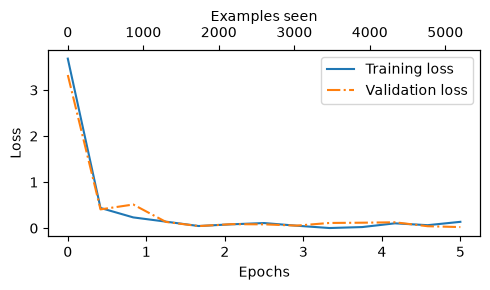

In [38]:
from previous_chapters import plot_values

epochs_tensor = torch.linspace(0, num_epochs, len(train_losses))
examples_seen_tensor = torch.linspace(0, examples_seen, len(train_losses))

plot_values(epochs_tensor, examples_seen_tensor, train_losses, val_losses, label="loss")

In [39]:
train_accuracy = calc_accuracy_loader(train_loader, model, device)
val_accuracy = calc_accuracy_loader(val_loader, model, device)
test_accuracy = calc_accuracy_loader(test_loader, model, device)

print(f"Training accuracy: {train_accuracy*100:.2f}%")
print(f"Validation accuracy: {val_accuracy*100:.2f}%")
print(f"Test accuracy: {test_accuracy*100:.2f}%")

Training accuracy: 99.52%
Validation accuracy: 98.66%
Test accuracy: 96.00%
